# Stage 07 — Class Imbalance & Controlled Evaluation

## Objective

Compare no resampling, SMOTE, ADASYN and Random Under-sampling on a valid common numerical
space. Moderate imbalance is verified rather than assumed: full labels 0/1=4,846/8,060;
inner training=3,064/5,109. Positive class 1 is the 90-day diagnosis group; minority 0 is its
complement ([target sources](01_eda.ipynb)). Clinical timing remains a separate limitation.

## Methodology

Use the same 69 numerical candidates, fixed LR and exact five grouped-fold recipe as Stage 06.
Exclude nominal codes/One-Hot to avoid synthetic categorical interpolation. This omits the five
nominal inputs in Stage 06, so recompute a numerical-only no-resampling reference.

Fit training-fold StandardScaler → kNN10 → completed StandardScaler → sampler → LR.
Held prediction transforms original records and skips sampling. SMOTE/ADASYN request ratio=1,
five neighbors and seed=42; RUS requests ratio=1, no replacement, seed=42. Oversampling adds
label 0; undersampling removes label 1. ADASYN rounding can miss exact balance.

$$x_{new}=x_i+u(x_j-x_i),\qquad u\sim U(0,1).$$

$$g_i=\operatorname{round}\!\left(G\,r_i/\sum_j r_j\right).$$

Select the highest five-fold mean F1-macro, exact ties baseline first. Precision/Recall/F1 use
positive label 1; both-class/macro metrics, continuous AUC, confusion counts and original held
prevalence are retained. Brier is probability error, not a pure calibration test. Fold SD is
descriptive under overlapping training folds. Sampling before splitting leaks neighbors/
geometry and synthetic relatives into evaluation and changes the assessment population.

Lock the complete choice before one internal reserved assessment on the original 2,652 rows.
No method/threshold is revised after that score; rerunning the identical locked configuration
only checks reproducibility. Prior whole-file EDA prevents an untouched external-cohort claim.

## Implementation

Recreate the verified folds without fitting Stage 06 models. All learned prediction steps
are fresh within each fitting fold; the shared module does not prepare a full-training model
matrix here. Actual arrays/counts and complete raw-input imbalanced-learn pipelines are kept
for interpretation and reproducibility. Synthetic leakage/sampler tests are in `tests/`. No categorical interpolation, clipping or retuning is added.

In [1]:
from pathlib import Path
import hashlib
import sys
from time import perf_counter
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML
from sklearn import config_context
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'myst.yml').is_file() and (p / 'src/validate_dataset.py').is_file()), None)
if ROOT is None or Path(sys.prefix) != ROOT / '.venv':
    raise RuntimeError('Start in the repository and use the hcmus-wids .venv kernel.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.tabular_data import load_data, split_data, numerical_columns, numeric_audit, CLINICAL_FIELDS, CATEGORICAL_FEATURES, REPRESENTATIVE_FEATURES, LR_SETTINGS, KNN_MEMORY_MIB

DATA_PATH = ROOT / 'data/raw/training.csv'
ID, TARGET, ZIP = 'patient_id', 'DiagPeriodL90D', 'patient_zip3'
df, raw_sha_before = load_data(ROOT)
train_index, validation_index, reserved_index = split_data(df)
clinical_fields = CLINICAL_FIELDS.copy()
FEATURES = REPRESENTATIVE_FEATURES.copy()
forbidden = clinical_fields | {ID, TARGET, ZIP, *CATEGORICAL_FEATURES, 'patient_gender'}
numerical_candidates = numerical_columns(df)
numerical_eligibility, bounded_share_features = numeric_audit(df, train_index, validation_index)
EXPANDED_FEATURES = numerical_candidates.copy()
air_features = {'Ozone', 'PM25', 'N02'}
stage03_adopted_training_rows = train_index.copy()  # Preserved keep-all decision before this stage's intervention.
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi':110, 'savefig.dpi':140})

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score
STAGE06_NUMERIC = numerical_candidates.copy()
STAGE06_CATEGORICAL = CATEGORICAL_FEATURES.copy()
STAGE06_LR = LR_SETTINGS.copy()
# Reproduce Stage 06's deterministic recipe, without fitting any Stage 06 model.
stage06_X = df.loc[train_index, STAGE06_NUMERIC+STAGE06_CATEGORICAL].copy(deep=True)
stage06_X[STAGE06_CATEGORICAL] = stage06_X[STAGE06_CATEGORICAL].astype(object).where(stage06_X[STAGE06_CATEGORICAL].notna(),np.nan)
stage06_y = df.loc[train_index,TARGET].copy()
stage06_groups = df.loc[train_index,ZIP].copy()
stage06_folds = list(StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=42).split(stage06_X,stage06_y,groups=stage06_groups))

### Observed class balance

In [2]:
from imblearn.pipeline import Pipeline as ImbalancedPipeline
from imblearn.over_sampling import SMOTE, ADASYN
from imblearn.under_sampling import RandomUnderSampler
from sklearn.metrics import precision_score, recall_score, confusion_matrix, brier_score_loss
import json

STAGE07_METHODS = ['No resampling', 'SMOTE', 'ADASYN', 'Random undersampling']
STAGE07_SEED = 42
STAGE07_FEATURES = list(STAGE06_NUMERIC)
stage07_X = df.loc[train_index, STAGE07_FEATURES].copy(deep=True)
stage07_y = df.loc[train_index, TARGET].copy()
assert len(STAGE07_FEATURES)==69 and stage07_X.index.equals(stage06_X.index)
assert set(STAGE07_FEATURES).isdisjoint({ID,TARGET,ZIP}|clinical_fields|set(STAGE06_CATEGORICAL))
stage07_class_audit = pd.DataFrame([
    {'Partition':name, 'N':len(index), 'Class 0':int(df.loc[index,TARGET].eq(0).sum()),
     'Class 1':int(df.loc[index,TARGET].eq(1).sum()),
     'Class 1 %':100*df.loc[index,TARGET].eq(1).mean(),
     'ZIP groups':df.loc[index,ZIP].nunique()}
    for name,index in [('Full file (EDA exposed)',df.index),('Inner training',train_index),
                       ('Other validation (not pooled)',validation_index),('Reserved',reserved_index)]
]).set_index('Partition')
display(stage07_class_audit.round(3))
print('Minority=0; positive label for Precision/Recall/AUC=1. Positive label 1 is the 90-day diagnosis group; minority label 0 is its complement.')

,N,Class 0,Class 1,Class 1 %,ZIP groups
Partition,,,,,
Full file (EDA exposed),12906,4846,8060,62.452,739
Inner training,8173,3064,5109,62.511,443
Other validation (not pooled),2081,778,1303,62.614,148
Reserved,2652,1004,1648,62.142,148


Minority=0; positive label for Precision/Recall/AUC=1. Positive label 1 is the 90-day diagnosis group; minority label 0 is its complement.


### Samplers and metrics

In [3]:
def make_stage07_preprocessor():
    return Pipeline([
        ('distance_scale', StandardScaler()),
        ('knn', KNNImputer(n_neighbors=10, weights='uniform', keep_empty_features=True)),
        ('completed_scale', StandardScaler())
    ])

def make_stage07_sampler(method):
    if method=='No resampling': return None
    if method=='SMOTE': return SMOTE(sampling_strategy=1., k_neighbors=5, random_state=STAGE07_SEED)
    if method=='ADASYN': return ADASYN(sampling_strategy=1., n_neighbors=5, random_state=STAGE07_SEED)
    if method=='Random undersampling':
        return RandomUnderSampler(sampling_strategy=1., replacement=False, random_state=STAGE07_SEED)
    raise ValueError(f'Unknown treatment: {method}')

def stage07_metrics(labels, prediction, probability):
    tn,fp,fn,tp = confusion_matrix(labels,prediction,labels=[0,1]).ravel()
    result = {'TN':int(tn), 'FP':int(fp), 'FN':int(fn), 'TP':int(tp),
        'F1 macro':f1_score(labels,prediction,average='macro',zero_division=0),
        'Precision macro':precision_score(labels,prediction,average='macro',zero_division=0),
        'Recall macro':recall_score(labels,prediction,average='macro',zero_division=0),
        'ROC AUC class1':roc_auc_score(labels,probability),
        'Brier class1':brier_score_loss(labels,probability),
        'Predicted class1 %':100*np.mean(np.asarray(prediction)==1)}
    for label in [0,1]:
        result[f'Precision class{label}']=precision_score(labels,prediction,pos_label=label,zero_division=0)
        result[f'Recall class{label}']=recall_score(labels,prediction,pos_label=label,zero_division=0)
        result[f'F1 class{label}']=f1_score(labels,prediction,pos_label=label,zero_division=0)
    return result

print('Methods:',STAGE07_METHODS,'; LR:',STAGE06_LR,'; threshold=0.5; identical fixed group-fold recipe reproduced.')

Methods: ['No resampling', 'SMOTE', 'ADASYN', 'Random undersampling'] ; LR: {'C': 1.0, 'l1_ratio': 0.0, 'solver': 'lbfgs', 'fit_intercept': True, 'max_iter': 2000, 'tol': 0.0001, 'class_weight': None, 'random_state': 42} ; threshold=0.5; identical fixed group-fold recipe reproduced.


### Training-only comparison

In [4]:
stage07_objects = {}
stage07_score_rows, stage07_count_rows, stage07_fit_rows = [], [], []
stage07_started = perf_counter()
with threadpool_limits(limits=1), config_context(working_memory=KNN_MEMORY_MIB):
    for fold,(fit_pos,held_pos) in enumerate(stage06_folds):
        fit_index,held_index = stage07_X.index[fit_pos],stage07_X.index[held_pos]
        assert set(df.loc[fit_index,ZIP]).isdisjoint(df.loc[held_index,ZIP])
        X_fit,y_fit = stage07_X.loc[fit_index],stage07_y.loc[fit_index]
        X_held,y_held = stage07_X.loc[held_index],stage07_y.loc[held_index]
        assert X_fit.columns.equals(X_held.columns) and y_fit.value_counts().min()>5
        start = perf_counter()
        preprocessor = make_stage07_preprocessor()
        z_fit = preprocessor.fit_transform(X_fit)
        preparation_seconds = perf_counter()-start
        assert z_fit.shape==(len(fit_index),69) and np.isfinite(z_fit).all()
        assert preprocessor.named_steps['completed_scale'].n_samples_seen_==len(fit_index)
        stage07_fit_rows.append({'Fold':fold,'Fit N':len(fit_index),'Held N':len(held_index),
            'Fit ZIPs':df.loc[fit_index,ZIP].nunique(),'Held ZIPs':df.loc[held_index,ZIP].nunique(),
            'ZIP overlap':0,'Features':69,'Shared preprocessing seconds':preparation_seconds})
        obj = {'fit_index':fit_index,'held_index':held_index,'preprocessor':preprocessor,
               'z_fit':z_fit,'treatments':{}}
        before = y_fit.value_counts().reindex([0,1])
        for method in STAGE07_METHODS:
            start = perf_counter()
            sampler = make_stage07_sampler(method)
            if sampler is None: X_res,y_res = z_fit.copy(),y_fit.to_numpy().copy()
            else: X_res,y_res = sampler.fit_resample(z_fit,y_fit.to_numpy())
            after = pd.Series(y_res).value_counts().reindex([0,1],fill_value=0)
            assert X_res.shape==(len(y_res),69) and np.isfinite(X_res).all()
            classifier = LogisticRegression(**STAGE06_LR).fit(X_res,y_res)
            pipeline = ImbalancedPipeline(preprocessor.steps+[
                ('sampler',sampler if sampler is not None else 'passthrough'),('classifier',classifier)])
            probability = pipeline.predict_proba(X_held)[:,1]
            prediction = (probability>=.5).astype(int)
            seconds = perf_counter()-start
            assert np.isfinite(probability).all() and classifier.classes_.tolist()==[0,1]
            stage07_score_rows.append({'Method':method,'Fold':fold,
                **stage07_metrics(y_held,prediction,probability),'Sampler + LR + prediction seconds':seconds})
            stage07_count_rows.append({'Method':method,'Fold':fold,
                'Fit 0':int(before[0]),'Fit 1':int(before[1]),'After 0':int(after[0]),'After 1':int(after[1]),
                'Added':max(0,len(y_res)-len(y_fit)),'Discarded':max(0,len(y_fit)-len(y_res)),
                'After class1 %':100*after[1]/len(y_res),
                'Held 0':int(y_held.eq(0).sum()),'Held 1':int(y_held.eq(1).sum())})
            obj['treatments'][method] = {'sampler':sampler,'pipeline':pipeline,'X_res':X_res,'y_res':y_res,
                'probability':probability,'prediction':prediction}
            print(f'Fold {fold} {method}: {before.to_dict()} → {after.to_dict()}; F1={stage07_score_rows[-1]["F1 macro"]:.6f}')
        stage07_objects[fold] = obj
stage07_cv_seconds = perf_counter()-stage07_started
stage07_scores = pd.DataFrame(stage07_score_rows)
stage07_counts = pd.DataFrame(stage07_count_rows)
stage07_fit_audit = pd.DataFrame(stage07_fit_rows).set_index('Fold')
display(stage07_fit_audit.round(4))
display(HTML('<details><summary>All 20 actual training / resampled / untouched held class counts</summary><div style="overflow:auto">'+stage07_counts.to_html(index=False,float_format='{:.3f}'.format)+'</div></details>'))
print('Total Stage 07 CV wall seconds:',stage07_cv_seconds)

Fold 0 No resampling: {0: 2452, 1: 4087} → {0: 2452, 1: 4087}; F1=0.437397


Fold 0 SMOTE: {0: 2452, 1: 4087} → {0: 4087, 1: 4087}; F1=0.499293


Fold 0 ADASYN: {0: 2452, 1: 4087} → {0: 4098, 1: 4087}; F1=0.502132


Fold 0 Random undersampling: {0: 2452, 1: 4087} → {0: 2452, 1: 2452}; F1=0.505405


Fold 1 No resampling: {0: 2447, 1: 4085} → {0: 2447, 1: 4085}; F1=0.409389


...

Fold 4 ADASYN: {0: 2453, 1: 4088} → {0: 4080, 1: 4088}; F1=0.495368


Fold 4 Random undersampling: {0: 2453, 1: 4088} → {0: 2453, 1: 2453}; F1=0.518893


,Fit N,Held N,Fit ZIPs,Held ZIPs,ZIP overlap,Features,Shared preprocessing seconds
Fold,,,,,,,
0,6539,1634,357,86,0,69,1.4979
1,6532,1641,362,81,0,69,1.3879
2,6541,1632,344,99,0,69,1.4197
3,6539,1634,362,81,0,69,1.3902
4,6541,1632,347,96,0,69,1.3875


Method,Fold,Fit 0,Fit 1,After 0,After 1,Added,Discarded,After class1 %,Held 0,Held 1
No resampling,0,2452,4087,2452,4087,0,0,62.502,612,1022
SMOTE,0,2452,4087,4087,4087,1635,0,50.000,612,1022
ADASYN,0,2452,4087,4098,4087,1646,0,49.933,612,1022
Random undersampling,0,2452,4087,2452,2452,0,1635,50.000,612,1022
No resampling,1,2447,4085,2447,4085,0,0,62.538,617,1024
SMOTE,1,2447,4085,4085,4085,1638,0,50.000,617,1024
ADASYN,1,2447,4085,4092,4085,1645,0,49.957,617,1024
Random undersampling,1,2447,4085,2447,2447,0,1638,50.000,617,1024
No resampling,2,2453,4088,2453,4088,0,0,62.498,611,1021
SMOTE,2,2453,4088,4088,4088,1635,0,50.000,611,1021


Total Stage 07 CV wall seconds: 15.305028875125572


## Results

The four-method table reports mean±fold SD, with all 20 fold metric/count/confusion rows
expandable. Confusion heatmaps share a common color scale. Training-distribution ECDFs and
all 1,380 feature diagnostics are supporting evidence. The final table scores only the
selected locked method on original reserved records; no baseline/resampler reserve search is made.

### Original-prevalence validation

,Precision class1,Recall class1,F1 macro,ROC AUC class1,Recall class0,Sampler + LR + prediction seconds
Method,,,,,,
No resampling,0.628064 ± 0.004525,0.956142 ± 0.022758,0.426654 ± 0.027742,0.533587 ± 0.024787,0.055493 ± 0.038001,1.960
SMOTE,0.639866 ± 0.022133,0.549589 ± 0.081786,0.507408 ± 0.017542,0.527965 ± 0.026273,0.480334 ± 0.103921,2.021
ADASYN,0.638552 ± 0.019155,0.543321 ± 0.058278,0.507336 ± 0.015890,0.528217 ± 0.024360,0.484659 ± 0.080689,2.158
Random undersampling,0.641183 ± 0.015931,0.559947 ± 0.103856,0.509298 ± 0.016373,0.528749 ± 0.026107,0.474508 ± 0.110716,1.815


Method,Fold,TN,FP,FN,TP,F1 macro,Precision macro,Recall macro,ROC AUC class1,Brier class1,Predicted class1 %,Precision class0,Recall class0,F1 class0,Precision class1,Recall class1,F1 class1,Sampler + LR + prediction seconds
No resampling,0,40,572,45,977,0.437397,0.550659,0.510664,0.527615,0.237143,94.798042,0.470588,0.065359,0.114778,0.630730,0.955969,0.760016,0.396291
SMOTE,0,247,365,413,609,0.499293,0.499750,0.499743,0.514704,0.250963,59.608323,0.374242,0.403595,0.388365,0.625257,0.595890,0.610220,0.437915
ADASYN,0,276,336,451,571,0.502132,0.504595,0.504844,0.524479,0.249420,55.507956,0.379642,0.450980,0.412248,0.629548,0.558708,0.592017,0.425870
Random undersampling,0,266,346,430,592,0.505405,0.506657,0.506948,0.526951,0.251295,57.405141,0.382184,0.434641,0.406728,0.631130,0.579256,0.604082,0.357741
No resampling,1,18,599,21,1003,0.409389,0.543815,0.504333,0.552889,0.233930,97.623400,0.461538,0.029173,0.054878,0.626092,0.979492,0.763899,0.413009
SMOTE,1,298,319,426,598,0.530311,0.531864,0.533483,0.544724,0.245927,55.880561,0.411602,0.482982,0.444444,0.652126,0.583984,0.616177,0.413032
ADASYN,1,279,338,414,610,0.522308,0.523029,0.523946,0.548692,0.245571,57.769653,0.402597,0.452188,0.425954,0.643460,0.595703,0.618661,0.437581
Random undersampling,1,269,348,379,645,0.532430,0.532335,0.532932,0.549727,0.244855,60.511883,0.415123,0.435981,0.425296,0.649547,0.629883,0.639564,0.366688
No resampling,2,32,579,41,980,0.426629,0.533482,0.506108,0.506614,0.238853,95.526961,0.438356,0.052373,0.093567,0.628608,0.959843,0.759690,0.381288
SMOTE,2,307,304,527,494,0.484035,0.493577,0.493147,0.502704,0.257459,48.897059,0.368106,0.502455,0.424913,0.619048,0.483839,0.543156,0.395794


Method,Precision class1 mean,Precision class1 std,Recall class1 mean,Recall class1 std,F1 class1 mean,F1 class1 std,Precision class0 mean,Precision class0 std,Recall class0 mean,Recall class0 std,F1 class0 mean,F1 class0 std,Precision macro mean,Precision macro std,Recall macro mean,Recall macro std,F1 macro mean,F1 macro std,ROC AUC class1 mean,ROC AUC class1 std,Brier class1 mean,Brier class1 std
No resampling,0.628064,0.004525,0.956142,0.022758,0.758003,0.005265,0.411054,0.103408,0.055493,0.038001,0.095305,0.058867,0.519559,0.053557,0.505818,0.009258,0.426654,0.027742,0.533587,0.024787,0.236120,0.002964
SMOTE,0.639866,0.022133,0.549589,0.081786,0.587967,0.045464,0.389052,0.019983,0.480334,0.103921,0.426849,0.048392,0.514459,0.020659,0.514961,0.021560,0.507408,0.017542,0.527965,0.026273,0.250836,0.004234
ADASYN,0.638552,0.019155,0.543321,0.058278,0.585319,0.031833,0.388016,0.018451,0.484659,0.080689,0.429353,0.039889,0.513284,0.018556,0.513990,0.019524,0.507336,0.015890,0.528217,0.024360,0.250231,0.003148
Random undersampling,0.641183,0.015931,0.559947,0.103856,0.592868,0.061726,0.393220,0.017074,0.474508,0.110716,0.425729,0.042626,0.517201,0.015410,0.517228,0.015556,0.509298,0.016373,0.528749,0.026107,0.251017,0.003741


F1-macro difference vs same-fold baseline,No resampling,SMOTE,ADASYN,Random undersampling
Fold,,,,
0,0.0,0.061896,0.064736,0.068008
1,0.0,0.120922,0.112919,0.123041
2,0.0,0.057406,0.064300,0.065583
3,0.0,0.050769,0.059661,0.031268
4,0.0,0.112778,0.101795,0.125320


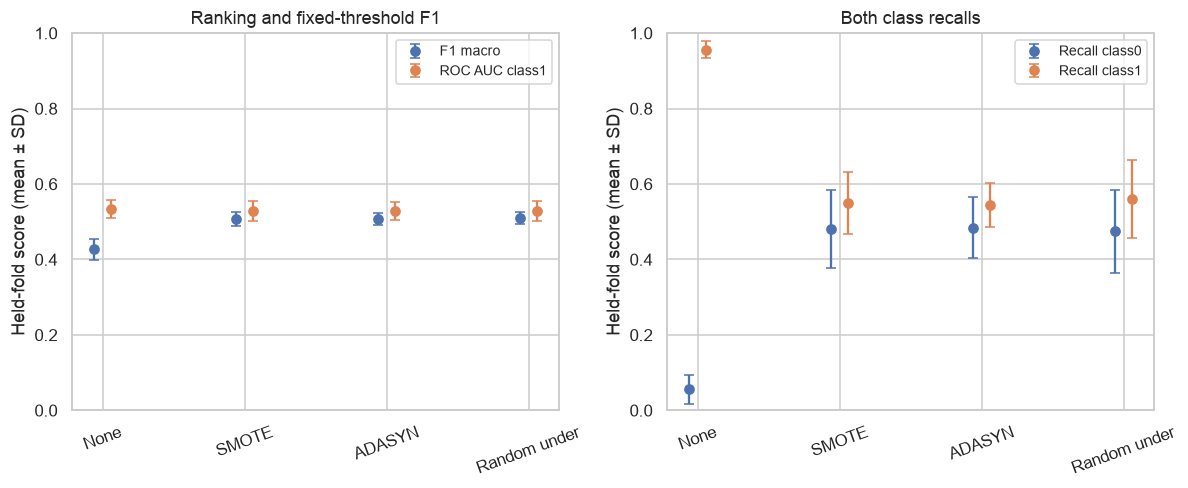

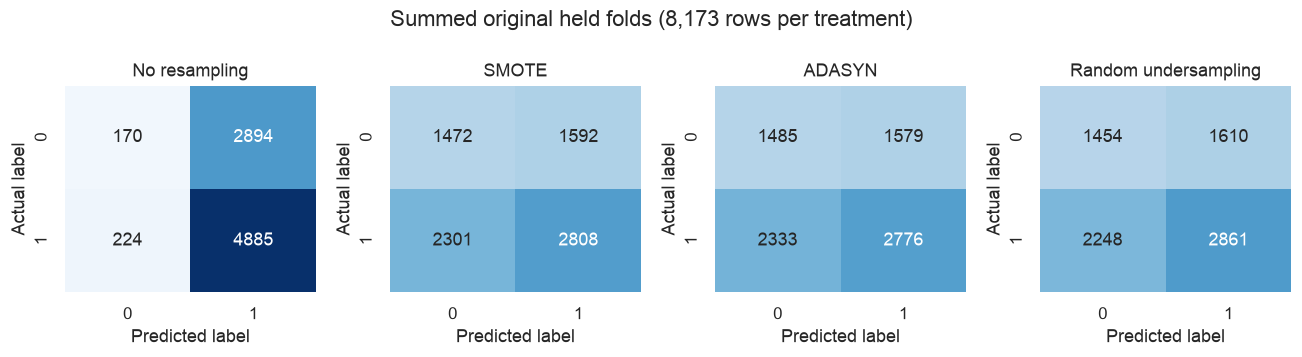

In [5]:
STAGE07_METRICS = ['Precision class1','Recall class1','F1 class1','Precision class0','Recall class0','F1 class0',
                   'Precision macro','Recall macro','F1 macro','ROC AUC class1','Brier class1']
stage07_summary = stage07_scores.groupby('Method',sort=False)[STAGE07_METRICS].agg(['mean','std']).reindex(STAGE07_METHODS)
stage07_summary.columns = [f'{metric} {stat}' for metric,stat in stage07_summary.columns]
stage07_display = pd.DataFrame({metric:stage07_summary[f'{metric} mean'].map('{:.6f}'.format)+' ± '+stage07_summary[f'{metric} std'].map('{:.6f}'.format)
    for metric in ['Precision class1','Recall class1','F1 macro','ROC AUC class1','Recall class0']})
stage07_display['Sampler + LR + prediction seconds'] = stage07_scores.groupby('Method')['Sampler + LR + prediction seconds'].sum().reindex(STAGE07_METHODS)
display(HTML('<div style="overflow:auto">'+stage07_display.to_html(float_format='{:.3f}'.format)+'</div>'))
for title,table in [('All 20 fold metrics / confusion counts / runtimes',stage07_scores),
                    ('All metric means and fold SDs',stage07_summary.reset_index())]:
    display(HTML('<details><summary>'+title+'</summary><div style="overflow:auto;max-height:32rem">'+table.to_html(index=False,float_format='{:.6f}'.format)+'</div></details>'))
stage07_paired = stage07_scores.pivot(index='Fold',columns='Method',values='F1 macro').reindex(columns=STAGE07_METHODS)
stage07_paired = stage07_paired.subtract(stage07_paired['No resampling'],axis=0)
display(stage07_paired.rename_axis(columns='F1-macro difference vs same-fold baseline').round(6))
fig,axes = plt.subplots(1,2,figsize=(11,4.6))
for ax,metrics,title in [(axes[0],['F1 macro','ROC AUC class1'],'Ranking and fixed-threshold F1'),
                          (axes[1],['Recall class0','Recall class1'],'Both class recalls')]:
    for offset,metric in enumerate(metrics):
        x = np.arange(4)+(offset-.5)*.12
        ax.errorbar(x,stage07_summary[f'{metric} mean'],yerr=stage07_summary[f'{metric} std'],fmt='o',capsize=3,label=metric)
    ax.set_xticks(range(4),['None','SMOTE','ADASYN','Random under'],rotation=20)
    ax.set(ylabel='Held-fold score (mean ± SD)',ylim=(0,1),title=title);ax.legend(fontsize=9)
plt.tight_layout();plt.show()
stage07_confusion_max = stage07_scores.groupby('Method')[['TN','FP','FN','TP']].sum().to_numpy().max()
fig,axes = plt.subplots(1,4,figsize=(12,3.3))
for ax,method in zip(axes,STAGE07_METHODS):
    row = stage07_scores[stage07_scores.Method.eq(method)][['TN','FP','FN','TP']].sum().to_numpy().reshape(2,2)
    sns.heatmap(row,annot=True,fmt='d',cbar=False,ax=ax,cmap='Blues',vmin=0,vmax=stage07_confusion_max,xticklabels=[0,1],yticklabels=[0,1])
    ax.set(title=method,xlabel='Predicted label',ylabel='Actual label')
fig.suptitle('Summed original held folds (8,173 rows per treatment)');plt.tight_layout();plt.show()

### Supporting distribution audit

,Mean_absolute_standardized_shift,Maximum_absolute_standardized_shift,Median_SD_ratio
Method,,,
No resampling,0.000000,0.000000,1.000000
SMOTE,0.006105,0.023850,0.995999
ADASYN,0.005041,0.012486,0.994529
Random undersampling,0.006799,0.025707,0.999001


,Synthetic N,Outside fitted column ranges,Fractional synthetic ages,"Synthetic share cells outside [0,100]"
Method,,,,
No resampling,0,0,0,0
SMOTE,8180,0,7500,0
ADASYN,8176,0,7619,0
Random undersampling,0,0,0,0


Fold,Method,Feature,Standardized mean shift,SD ratio
0,No resampling,patient_age,0.000000,1.000000
0,No resampling,bmi,-0.000000,1.000000
0,No resampling,population,0.000000,1.000000
0,No resampling,density,0.000000,1.000000
0,No resampling,age_median,0.000000,1.000000
0,No resampling,age_under_10,0.000000,1.000000
0,No resampling,age_10_to_19,0.000000,1.000000
0,No resampling,age_20s,-0.000000,1.000000
0,No resampling,age_30s,0.000000,1.000000
0,No resampling,age_40s,0.000000,1.000000


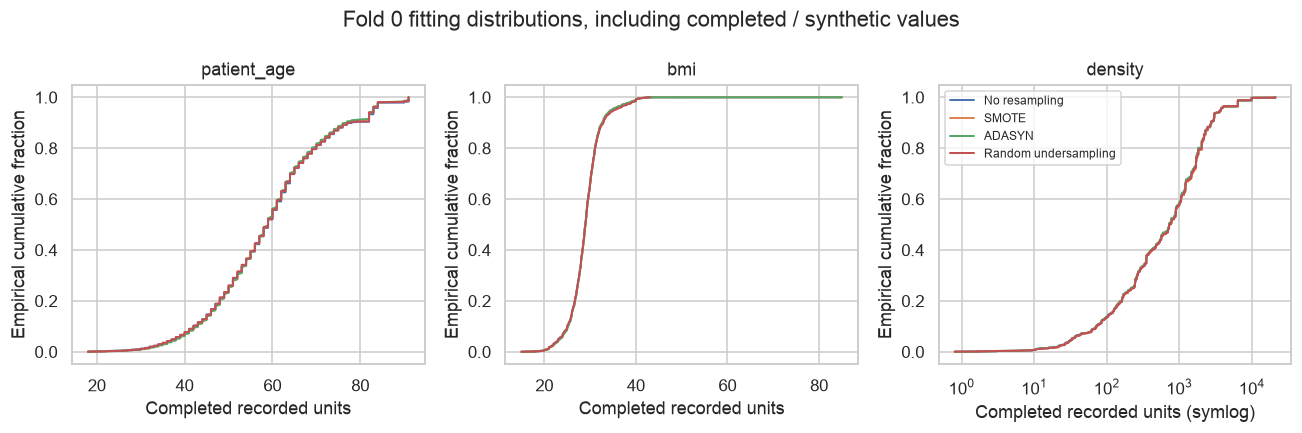

In [6]:
stage07_distribution_rows, stage07_support_rows = [], []
with threadpool_limits(limits=1):
    for fold,obj in stage07_objects.items():
        original = obj['z_fit']
        before_sd = original.std(axis=0,ddof=0)
        prep = obj['preprocessor']
        for method,result in obj['treatments'].items():
            values = result['X_res']
            mean_shift = values.mean(axis=0)-original.mean(axis=0)
            sd_ratio = np.divide(values.std(axis=0,ddof=0),before_sd,
                out=np.full(69,np.nan),where=before_sd>0)
            for feature,shift,ratio in zip(STAGE07_FEATURES,mean_shift,sd_ratio):
                stage07_distribution_rows.append({'Fold':fold,'Method':method,'Feature':feature,
                    'Standardized mean shift':shift,'SD ratio':ratio})
            synthetic = values[len(original):] if method in ['SMOTE','ADASYN'] else np.empty((0,69))
            support = {'Fold':fold,'Method':method,'Synthetic N':len(synthetic),'Outside fitted column ranges':0,
                       'Fractional synthetic ages':0,'Synthetic share cells outside [0,100]':0}
            if len(synthetic):
                support['Outside fitted column ranges'] = int(((synthetic<original.min(axis=0)-1e-10)|(synthetic>original.max(axis=0)+1e-10)).sum())
                raw_synthetic = prep.named_steps['distance_scale'].inverse_transform(
                    prep.named_steps['completed_scale'].inverse_transform(synthetic))
                age = raw_synthetic[:,STAGE07_FEATURES.index('patient_age')]
                support['Fractional synthetic ages'] = int((~np.isclose(age,np.round(age),rtol=0,atol=1e-8)).sum())
                shares = raw_synthetic[:,[STAGE07_FEATURES.index(c) for c in bounded_share_features]]
                support['Synthetic share cells outside [0,100]'] = int(((shares < -1e-8)|(shares > 100+1e-8)).sum())
            stage07_support_rows.append(support)
stage07_distributions = pd.DataFrame(stage07_distribution_rows)
stage07_support = pd.DataFrame(stage07_support_rows)
stage07_distribution_summary = stage07_distributions.groupby('Method',sort=False).agg(
    Mean_absolute_standardized_shift=('Standardized mean shift',lambda values:values.abs().mean()),
    Maximum_absolute_standardized_shift=('Standardized mean shift',lambda values:values.abs().max()),
    Median_SD_ratio=('SD ratio','median')).reindex(STAGE07_METHODS)
display(stage07_distribution_summary.round(6))
display(stage07_support.groupby('Method',sort=False).sum(numeric_only=True).drop(columns='Fold').reindex(STAGE07_METHODS))
display(HTML('<details><summary>All 1,380 fold / treatment / feature distribution diagnostics</summary><div style="overflow:auto;max-height:32rem">'+stage07_distributions.to_html(index=False,float_format='{:.6f}'.format)+'</div></details>'))
fig,axes = plt.subplots(1,3,figsize=(12,4))
obj = stage07_objects[0]
for ax,feature in zip(axes,['patient_age','bmi','density']):
    column = STAGE07_FEATURES.index(feature)
    for method in STAGE07_METHODS:
        values = obj['treatments'][method]['X_res'][:,column]
        raw_values = values*obj['preprocessor'].named_steps['completed_scale'].scale_[column]+obj['preprocessor'].named_steps['completed_scale'].mean_[column]
        raw_values = raw_values*obj['preprocessor'].named_steps['distance_scale'].scale_[column]+obj['preprocessor'].named_steps['distance_scale'].mean_[column]
        ordered = np.sort(raw_values)
        ax.plot(ordered,np.arange(1,len(ordered)+1)/len(ordered),label=method,linewidth=1.3)
    if feature=='density':ax.set_xscale('symlog',linthresh=1)
    ax.set(title=feature,xlabel='Completed recorded units'+(' (symlog)' if feature=='density' else ''),ylabel='Empirical cumulative fraction')
axes[-1].legend(fontsize=8);fig.suptitle('Fold 0 fitting distributions, including completed / synthetic values');plt.tight_layout();plt.show()

### Locked internal reserved assessment

In [7]:
stage07_selected = stage07_summary['F1 macro mean'].idxmax()
stage07_lock = {'selection':'maximum five-fold mean F1-macro; exact ties baseline first',
    'method':stage07_selected,'features':STAGE07_FEATURES,'seed':STAGE07_SEED,
    'preprocessing':'fit-only StandardScaler -> kNN(10,uniform) -> completed StandardScaler',
    'sampler':str(make_stage07_sampler(stage07_selected)),
    'LR':STAGE06_LR.copy(),'threshold':.5,'fit_rows':len(train_index),'fit_partitions':['inner training'],
    'assessment':'one post-EDA internal reserved assessment; no clinical eligibility approval'}
stage07_lock_json = json.dumps(stage07_lock,sort_keys=True)
from html import escape
display(HTML('<details><summary>Locked policy before reserved scoring</summary><pre>'
    + escape(stage07_lock_json) + '</pre></details>'))
stage07_final_sampler = make_stage07_sampler(stage07_selected)
with threadpool_limits(limits=1),config_context(working_memory=KNN_MEMORY_MIB):
    start = perf_counter()
    stage07_final_preprocessor = make_stage07_preprocessor()
    stage07_final_z = stage07_final_preprocessor.fit_transform(stage07_X)
    if stage07_final_sampler is None:
        stage07_final_values,stage07_final_labels = stage07_final_z.copy(),stage07_y.to_numpy().copy()
    else:
        stage07_final_values,stage07_final_labels = stage07_final_sampler.fit_resample(stage07_final_z,stage07_y.to_numpy())
    stage07_final_classifier = LogisticRegression(**STAGE06_LR).fit(stage07_final_values,stage07_final_labels)
    stage07_final_pipeline = ImbalancedPipeline(stage07_final_preprocessor.steps+[
        ('sampler',stage07_final_sampler if stage07_final_sampler is not None else 'passthrough'),
        ('classifier',stage07_final_classifier)])
    stage07_reserved_probability = stage07_final_pipeline.predict_proba(df.loc[reserved_index,STAGE07_FEATURES])[:,1]
    stage07_final_seconds = perf_counter()-start
stage07_reserved_prediction = (stage07_reserved_probability>=.5).astype(int)
stage07_reserved_metrics = stage07_metrics(df.loc[reserved_index,TARGET],stage07_reserved_prediction,stage07_reserved_probability)
stage07_final_counts = {int(key):int(value) for key,value in Counter(stage07_final_labels).items()}
print('Actual final fitting counts:',stage07_final_counts)
stage07_reserved_table = pd.DataFrame([{'Method':stage07_selected,'Reserved N':len(reserved_index),
    'Reserved class0':int(df.loc[reserved_index,TARGET].eq(0).sum()),
    'Reserved class1':int(df.loc[reserved_index,TARGET].eq(1).sum()),**stage07_reserved_metrics,
    'Fit + reserved prediction seconds':stage07_final_seconds}])
display(HTML('<div style="overflow:auto">'+stage07_reserved_table.to_html(index=False,float_format='{:.6f}'.format)+'</div>'))
print('This is one internal reserved point estimate, not a comparative or external clinical test.')

Actual final fitting counts: {0: 3064, 1: 3064}


Method,Reserved N,Reserved class0,Reserved class1,TN,FP,FN,TP,F1 macro,Precision macro,Recall macro,ROC AUC class1,Brier class1,Predicted class1 %,Precision class0,Recall class0,F1 class0,Precision class1,Recall class1,F1 class1,Fit + reserved prediction seconds
Random undersampling,2652,1004,1648,599,405,916,732,0.500629,0.519590,0.520394,0.529792,0.261664,42.873303,0.395380,0.596614,0.475586,0.643799,0.444175,0.525673,3.198725


This is one internal reserved point estimate, not a comparative or external clinical test.


## Discussion

RUS has the highest mean F1-macro (0.509298±0.016373), versus numerical baseline
0.426654±0.027742, SMOTE 0.507408 and ADASYN 0.507336. Its advantage over other resamplers
is small relative to fold variation. Class-0 recall rises from 0.055493 to 0.474508 while
class-1 recall falls from 0.956142 to 0.559947. AUC falls slightly (0.533587→0.528749), and
Brier worsens (0.236120→0.251017): better threshold F1 is not better ranking/probabilities.

ADASYN creates 8,176 synthetic records across overlapping fits, versus SMOTE's 8,180; actual
counts take precedence over requested balance. Fractional synthetic ages/context mixtures
remain despite finite values and convex bounds. RUS discards information and changes the
training prior. The final RUS fit has 3,064 records per class, discarding 2,045 majority rows;
reserved F1=0.500629, AUC=0.529792, confusion [[599,405],[916,732]]. This estimates one
post-EDA internal pipeline and cannot establish reserve improvement over an unscored baseline.

In [8]:
stage07_baseline = stage07_summary.loc['No resampling']
stage07_best = stage07_summary.loc[stage07_selected]
stage07_delta = stage07_best['F1 macro mean']-stage07_baseline['F1 macro mean']
stage07_findings = pd.DataFrame([
    {'Finding':'Observed development winner','Evidence':f"{stage07_selected}; F1={stage07_best['F1 macro mean']:.6f} ± {stage07_best['F1 macro std']:.6f}; delta={stage07_delta:+.6f}",
     'Implication':'Candidate for this fixed numerical LR protocol; fold SD is not an independent CI'},
    {'Finding':'Class trade-off','Evidence':f"Baseline recalls 0/1={stage07_baseline['Recall class0 mean']:.4f}/{stage07_baseline['Recall class1 mean']:.4f}; selected={stage07_best['Recall class0 mean']:.4f}/{stage07_best['Recall class1 mean']:.4f}",
     'Implication':'Interpret jointly with both precisions and F1, not minority recall alone'},
    {'Finding':'Ranking','Evidence':f"Baseline/selected AUC={stage07_baseline['ROC AUC class1 mean']:.4f}/{stage07_best['ROC AUC class1 mean']:.4f}",
     'Implication':'Resampling can alter threshold behavior without strong ranking gains'},
    {'Finding':'Probability error','Evidence':f"Baseline/selected mean Brier={stage07_baseline['Brier class1 mean']:.6f}/{stage07_best['Brier class1 mean']:.6f}",
     'Implication':'Higher selected Brier is worse probability error; the F1 gain does not imply improved probabilities or calibration'},
    {'Finding':'Synthetic/data losses','Evidence':f"SMOTE/ADASYN synthetic totals across five fits={stage07_counts.loc[stage07_counts.Method.eq('SMOTE'),'Added'].sum()}/{stage07_counts.loc[stage07_counts.Method.eq('ADASYN'),'Added'].sum()}; RUS discards={stage07_counts.Discarded.sum()}",
     'Implication':'Counts aggregate overlapping training fits; not unique real patients'},
    {'Finding':'Locked internal assessment','Evidence':f"{stage07_selected}: reserved F1={stage07_reserved_metrics['F1 macro']:.6f}; AUC={stage07_reserved_metrics['ROC AUC class1']:.6f}",
     'Implication':'Only one locked method scored; no comparative reserve or untouched-external claim'},
    {'Finding':'Scope and realism','Evidence':'69 numerical inputs; no nominal codes/OHE interpolation; fractional ages/context mixing audited',
     'Implication':'Retrospective benchmark only; validate clinical time contract and synthetic constraints'},
    {'Finding':'Completion boundary','Evidence':'Four-method five-fold comparison and one locked assessment implemented',
     'Implication':'External/prospective validation, cost/calibration and independent missingness assumptions remain unresolved; Text not performed'}
])
display(HTML('<div style="overflow:auto">'+stage07_findings.to_html(index=False)+'</div>'))
print('Treatment supported for this protocol:',stage07_selected,
      '; evidence is descriptive internal performance, not proof of clinical superiority.')

Finding,Evidence,Implication
Observed development winner,Random undersampling; F1=0.509298 ± 0.016373; delta=+0.082644,Candidate for this fixed numerical LR protocol; fold SD is not an independent CI
Class trade-off,Baseline recalls 0/1=0.0555/0.9561; selected=0.4745/0.5599,"Interpret jointly with both precisions and F1, not minority recall alone"
Ranking,Baseline/selected AUC=0.5336/0.5287,Resampling can alter threshold behavior without strong ranking gains
Probability error,Baseline/selected mean Brier=0.236120/0.251017,Higher selected Brier is worse probability error; the F1 gain does not imply improved probabilities or calibration
Synthetic/data losses,SMOTE/ADASYN synthetic totals across five fits=8180/8176; RUS discards=8180,Counts aggregate overlapping training fits; not unique real patients
Locked internal assessment,Random undersampling: reserved F1=0.500629; AUC=0.529792,Only one locked method scored; no comparative reserve or untouched-external claim
Scope and realism,69 numerical inputs; no nominal codes/OHE interpolation; fractional ages/context mixing audited,Retrospective benchmark only; validate clinical time contract and synthetic constraints
Completion boundary,Four-method five-fold comparison and one locked assessment implemented,"External/prospective validation, cost/calibration and independent missingness assumptions remain unresolved; Text not performed"


Treatment supported for this protocol: Random undersampling ; evidence is descriptive internal performance, not proof of clinical superiority.


## Conclusion

RUS is the declared candidate for this fixed numerical LR/F1 protocol, with no clinical or
universal superiority claim. Original held prevalence, raw data, configurations and scientific
decisions are preserved. Part A now covers the requested comparisons; unresolved timing,
missingness calibration, synthetic realism, external validity and rubric interpretation are
reported honestly in the [current audit](../../RUBRIC_AUDIT.md). Part B remains outside this work.

In [9]:
assert len(stage07_scores) == 4*5
assert sum(stage07_reserved_metrics[key] for key in ["TN", "FP", "FN", "TP"]) == len(reserved_index)
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == raw_sha_before, "Raw CSV changed"
print(f"Completed four treatments on five grouped folds and one locked {stage07_selected} reserved assessment at original prevalence.")

Completed four treatments on five grouped folds and one locked Random undersampling reserved assessment at original prevalence.
